# DenseNet121 Chest Disease Classification — NIH ChestXray14
Cleaned, single-run version of the notebook. Every cell only runs once, in the correct order, and every variable is defined before it is used.

In [3]:
# ============================================================
# Imports
# ============================================================

import os
import cv2
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.amp import autocast, GradScaler

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    hamming_loss
)

warnings.filterwarnings("ignore")

print("Libraries Imported Successfully.")

Libraries Imported Successfully.


In [4]:
# ============================================================
# Configuration
# ============================================================

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 14          # will be re-confirmed once CLASS_NAMES is built
THRESHOLD = 0.5
NUM_WORKERS = 2
PIN_MEMORY = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", DEVICE)

Device : cuda


In [5]:
# ============================================================
# Reproducibility
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random Seed Set Successfully.")

Random Seed Set Successfully.


In [6]:
# ============================================================
# Download NIH ChestXray14 Dataset
# ============================================================

import kagglehub

DATASET_PATH = kagglehub.dataset_download(
    "khanfashee/nih-chest-x-ray-14-224x224-resized"
)

print("=" * 70)
print("Dataset Downloaded Successfully")
print("=" * 70)
print(DATASET_PATH)

Dataset Downloaded Successfully
/home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3


In [7]:
# ============================================================
# Dataset Paths
# ============================================================

CSV_FILE = os.path.join(DATASET_PATH, "Data_Entry_2017.csv")

IMAGE_DIR = os.path.join(DATASET_PATH, "images-224", "images-224")

print("=" * 70)
print("CSV File  :", CSV_FILE)
print("Image Dir :", IMAGE_DIR)
print("=" * 70)

CSV File  : /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/Data_Entry_2017.csv
Image Dir : /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224/images-224


In [8]:
# ============================================================
# Load Metadata CSV
# ============================================================

df = pd.read_csv(CSV_FILE)

print("=" * 70)
print("Total Records :", len(df))
print("=" * 70)
df.head()

Total Records : 112120


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,058Y,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,058Y,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,058Y,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,081Y,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,081Y,F,PA,2582,2991,0.143,0.143,NaN


In [7]:
# ============================================================
# Disease Classes
# ============================================================

CLASS_NAMES = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

NUM_CLASSES = len(CLASS_NAMES)

print("Number of Diseases :", NUM_CLASSES)
print()
for i, disease in enumerate(CLASS_NAMES):
    print(f"{i+1}. {disease}")

Number of Diseases : 14

1. Atelectasis
2. Cardiomegaly
3. Effusion
4. Infiltration
5. Mass
6. Nodule
7. Pneumonia
8. Pneumothorax
9. Consolidation
10. Edema
11. Emphysema
12. Fibrosis
13. Pleural_Thickening
14. Hernia


In [8]:
# ============================================================
# Train / Validation / Test Split
# ============================================================
# 70% Train, 15% Validation, 15% Test.
# Validation is used during training to pick the best checkpoint.
# Test is held out completely and only touched once, at the end.

VAL_SIZE = 0.15
TEST_SIZE = 0.15

train_df, temp_df = train_test_split(
    df,
    test_size=(VAL_SIZE + TEST_SIZE),
    random_state=SEED,
    shuffle=True
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=(TEST_SIZE / (VAL_SIZE + TEST_SIZE)),
    random_state=SEED,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("=" * 70)
print("Training Images   :", len(train_df))
print("Validation Images :", len(val_df))
print("Testing Images    :", len(test_df))
print("=" * 70)

Training Images   : 78484
Validation Images : 16818
Testing Images    : 16818


In [9]:
# ============================================================
# Image Enhancement — CLAHE + Unsharp Mask
# ============================================================

def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(image)


def apply_unsharp_mask(image, kernel_size=(5, 5), sigma=1.0, amount=1.5):
    blurred = cv2.GaussianBlur(image, kernel_size, sigma)
    sharpened = cv2.addWeighted(image, 1 + amount, blurred, -amount, 0)
    sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)
    return sharpened


def enhance_image(image):
    image = apply_clahe(image)
    image = apply_unsharp_mask(image)
    return image

print("Image Enhancement Loaded Successfully")

Image Enhancement Loaded Successfully


In [10]:
# ============================================================
# Image Transformations
# ============================================================

train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Transforms Ready")

Transforms Ready


In [11]:
# ============================================================
# ChestXray Dataset
# ============================================================

class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, image_dir, train=True):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.train = train

    def __len__(self):
        return len(self.df)

    def encode_labels(self, labels):
        target = np.zeros(NUM_CLASSES, dtype=np.float32)

        if labels == "No Finding":
            return target

        for disease in labels.split("|"):
            disease = disease.strip()
            if disease in CLASS_NAMES:
                target[CLASS_NAMES.index(disease)] = 1.0

        return target

    def __getitem__(self, idx):
        image_name = self.df.loc[idx, "Image Index"]
        labels = self.df.loc[idx, "Finding Labels"]

        image_path = os.path.join(self.image_dir, image_name)

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise FileNotFoundError(image_path)

        original = image.copy()

        # CLAHE + Unsharp
        image = enhance_image(image)

        # Resize
        image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE))

        # Grayscale -> RGB
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)

        # Transform
        if self.train:
            image = train_transform(image)
        else:
            image = test_transform(image)

        target = torch.tensor(self.encode_labels(labels), dtype=torch.float32)

        return image, target, original

print("Dataset Class Ready")

Dataset Class Ready


In [12]:
# ============================================================
# Create Dataset Objects
# ============================================================

train_dataset = ChestXrayDataset(dataframe=train_df, image_dir=IMAGE_DIR, train=True)
val_dataset = ChestXrayDataset(dataframe=val_df, image_dir=IMAGE_DIR, train=False)
test_dataset = ChestXrayDataset(dataframe=test_df, image_dir=IMAGE_DIR, train=False)

print("=" * 60)
print("Training Images   :", len(train_dataset))
print("Validation Images :", len(val_dataset))
print("Testing Images    :", len(test_dataset))
print("=" * 60)

Training Images   : 78484
Validation Images : 16818
Testing Images    : 16818


In [13]:
# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)

print("=" * 60)
print("Train Batches      :", len(train_loader))
print("Validation Batches :", len(val_loader))
print("Test Batches       :", len(test_loader))
print("=" * 60)

Train Batches      : 2453
Validation Batches : 526
Test Batches       : 526


In [14]:
# ============================================================
# Verify DataLoader
# ============================================================

images, labels, originals = next(iter(train_loader))

print("=" * 60)
print("Image Batch Shape :", images.shape)
print("Label Shape       :", labels.shape)
print("Original Images   :", len(originals))
print("=" * 60)

Image Batch Shape : torch.Size([32, 3, 224, 224])
Label Shape       : torch.Size([32, 14])
Original Images   : 32


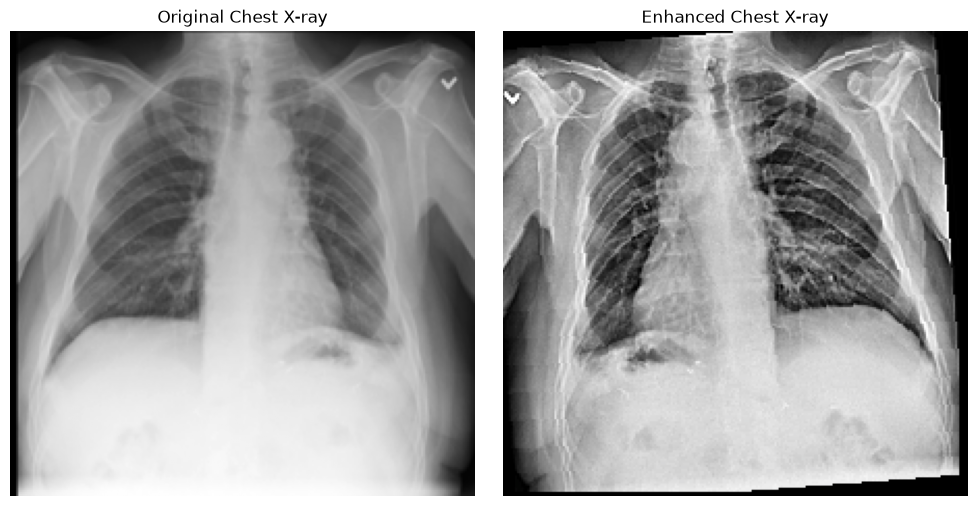

Positive Diseases


In [15]:
# ============================================================
# Visualize Sample — Original vs Enhanced
# ============================================================

img = images[0].permute(1, 2, 0).numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

img = img * std + mean
img = np.clip(img, 0, 1)

original_img = originals[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_img, cmap="gray")
axes[0].set_title("Original Chest X-ray")
axes[0].axis("off")

axes[1].imshow(img)
axes[1].set_title("Enhanced Chest X-ray")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Positive Diseases")
for i in range(NUM_CLASSES):
    if labels[0][i] == 1:
        print("-", CLASS_NAMES[i])

In [16]:
# ============================================================
# DenseNet121 Model
# ============================================================

class DenseNet121Model(nn.Module):

    def __init__(self, num_classes=NUM_CLASSES, pretrained=True,
                 dropout_rate=0.3, freeze_backbone=False):
        super().__init__()

        # ----------------------------------------------------
        # Load Pretrained DenseNet121
        # ----------------------------------------------------
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        self.backbone = models.densenet121(weights=weights)

        # ----------------------------------------------------
        # Feature Dimension
        # ----------------------------------------------------
        self.feature_dim = self.backbone.classifier.in_features

        # ----------------------------------------------------
        # Remove Original Classifier
        # ----------------------------------------------------
        self.backbone.classifier = nn.Identity()

        # ----------------------------------------------------
        # Freeze Backbone
        # ----------------------------------------------------
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        # ----------------------------------------------------
        # Classification Head
        # ----------------------------------------------------
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.feature_dim, num_classes)

        # ----------------------------------------------------
        # Weight Initialization
        # ----------------------------------------------------
        nn.init.kaiming_normal_(self.classifier.weight, mode="fan_out", nonlinearity="relu")
        nn.init.constant_(self.classifier.bias, 0)

    def forward(self, x):
        features = self.backbone(x)
        features = self.dropout(features)
        logits = self.classifier(features)

        return {
            "features": features,
            "logits": logits
        }

print("=" * 60)
print("DenseNet121 Model Class Defined Successfully")
print("=" * 60)

DenseNet121 Model Class Defined Successfully


In [17]:
# ============================================================
# Verify DenseNet121 Model
# ============================================================

model = DenseNet121Model(pretrained=True).to(DEVICE)

dummy = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)

outputs = model(dummy)

print("=" * 60)
print("Device :", DEVICE)
print()
print("Input Shape   :", dummy.shape)
print("Feature Shape :", outputs["features"].shape)
print("Output Shape  :", outputs["logits"].shape)
print()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Total Parameters     :", f"{total_params:,}")
print("Trainable Parameters :", f"{trainable_params:,}")
print("=" * 60)

Device : cuda

Input Shape   : torch.Size([2, 3, 224, 224])
Feature Shape : torch.Size([2, 1024])
Output Shape  : torch.Size([2, 14])

Total Parameters     : 6,968,206
Trainable Parameters : 6,968,206


In [18]:
# ============================================================
# Training Components
# ============================================================

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("=" * 60)
print("Loss Function :", type(criterion).__name__)
print("Optimizer     :", type(optimizer).__name__)
print("Scheduler     :", type(scheduler).__name__)
print("=" * 60)

Loss Function : BCEWithLogitsLoss
Optimizer     : AdamW
Scheduler     : ReduceLROnPlateau


In [19]:
# ============================================================
# Freeze & Unfreeze DenseNet Backbone
# ============================================================

def freeze_backbone():
    print("Freezing DenseNet Backbone...")
    for param in model.backbone.features.parameters():
        param.requires_grad = False
    print("Backbone Frozen")


def unfreeze_backbone():
    print("Unfreezing DenseNet Backbone...")
    for param in model.backbone.features.parameters():
        param.requires_grad = True
    print("Backbone Trainable")


freeze_backbone()

Freezing DenseNet Backbone...
Backbone Frozen


In [20]:
# ============================================================
# Mixed Precision & Training Configuration
# ============================================================

scaler = GradScaler("cuda") if torch.cuda.is_available() else GradScaler()

FREEZE_EPOCHS = 3
EARLY_STOPPING_PATIENCE = 8

best_auc = 0.0
best_epoch = 0
epochs_without_improvement = 0

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "precision": [],
    "recall": [],
    "f1": [],
    "auroc": [],
    "learning_rate": []
}

os.makedirs("checkpoints", exist_ok=True)

BEST_MODEL_PATH = "checkpoints/best_model.pth"
LAST_MODEL_PATH = "checkpoints/last_model.pth"

print("=" * 60)
print("Training Configuration Ready")
print("=" * 60)

Training Configuration Ready


In [21]:
# ============================================================
# Train One Epoch
# ============================================================

def train_one_epoch(epoch):
    model.train()
    running_loss = 0.0

    progress_bar = tqdm(train_loader, desc=f"Epoch [{epoch}/{EPOCHS}] Training", leave=False)

    for images, labels, _ in progress_bar:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # --------------------------------------------------
        # Mixed Precision Forward
        # --------------------------------------------------
        with autocast(device_type=DEVICE.type, enabled=torch.cuda.is_available()):
            outputs = model(images)
            logits = outputs["logits"]
            loss = criterion(logits, labels)

        # --------------------------------------------------
        # Backpropagation
        # --------------------------------------------------
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        progress_bar.set_postfix({
            "Loss": f"{loss.item():.4f}",
            "LR": f"{optimizer.param_groups[0]['lr']:.6f}"
        })

    epoch_loss = running_loss / len(train_loader)
    return epoch_loss

print("train_one_epoch() Ready")

train_one_epoch() Ready


In [22]:
# ============================================================
# Validation / Evaluation
# ============================================================
# Pass val_loader during training (model selection) and
# test_loader exactly once at the end (final, held-out score).

def validate(loader, desc="Validation"):
    model.eval()
    running_loss = 0.0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        progress_bar = tqdm(loader, desc=desc, leave=False)

        for images, labels, _ in progress_bar:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with autocast(device_type=DEVICE.type, enabled=torch.cuda.is_available()):
                outputs = model(images)
                logits = outputs["logits"]
                loss = criterion(logits, labels)

            running_loss += loss.item()

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= THRESHOLD).float()

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)
    all_probabilities = np.array(all_probabilities)

    val_loss = running_loss / len(loader)

    accuracy = accuracy_score(all_labels.flatten(), all_predictions.flatten())
    precision = precision_score(all_labels.flatten(), all_predictions.flatten(), zero_division=0)
    recall = recall_score(all_labels.flatten(), all_predictions.flatten(), zero_division=0)
    f1 = f1_score(all_labels.flatten(), all_predictions.flatten(), zero_division=0)

    try:
        auroc = roc_auc_score(all_labels, all_probabilities, average="macro")
    except ValueError:
        auroc = 0.0

    return val_loss, accuracy, precision, recall, f1, auroc

print("validate() Ready")

validate() Ready


In [23]:
# ============================================================
# Main Training Loop
# ============================================================

start_time = time.time()

print("=" * 70)
print("Starting DenseNet121 Training")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):

    print("\n" + "=" * 70)
    print(f"Epoch {epoch}/{EPOCHS}")
    print("=" * 70)

    # --------------------------------------------------------
    # Unfreeze Backbone After the Freeze Phase
    # --------------------------------------------------------
    if epoch == FREEZE_EPOCHS + 1:
        unfreeze_backbone()

        optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

        print("Fine-tuning Started.")

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    train_loss = train_one_epoch(epoch)

    # --------------------------------------------------------
    # Validation (never touches the held-out test set)
    # --------------------------------------------------------
    val_loss, accuracy, precision, recall, f1, auroc = validate(val_loader, desc="Validation")

    scheduler.step(auroc)
    current_lr = optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # Save History
    # --------------------------------------------------------
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["accuracy"].append(accuracy)
    history["precision"].append(precision)
    history["recall"].append(recall)
    history["f1"].append(f1)
    history["auroc"].append(auroc)
    history["learning_rate"].append(current_lr)

    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------
    print()
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Accuracy   : {accuracy:.4f}")
    print(f"Precision  : {precision:.4f}")
    print(f"Recall     : {recall:.4f}")
    print(f"F1 Score   : {f1:.4f}")
    print(f"AUROC      : {auroc:.4f}")
    print(f"LR         : {current_lr:.7f}")

    # --------------------------------------------------------
    # Save Best Model
    # --------------------------------------------------------
    if auroc > best_auc:
        best_auc = auroc
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "best_auc": best_auc,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict()
        }, BEST_MODEL_PATH)

        print("\nBest Model Saved.")
    else:
        epochs_without_improvement += 1
        print(f"No Improvement ({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})")

    # --------------------------------------------------------
    # Save Last Model
    # --------------------------------------------------------
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict()
    }, LAST_MODEL_PATH)

    # --------------------------------------------------------
    # Early Stopping
    # --------------------------------------------------------
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly Stopping Triggered.")
        break

training_time = (time.time() - start_time) / 60

print()
print("=" * 70)
print("Training Completed")
print("=" * 70)
print(f"Best Epoch : {best_epoch}")
print(f"Best AUROC : {best_auc:.4f}")
print(f"Training Time : {training_time:.2f} Minutes")

Starting DenseNet121 Training

Epoch 1/50



Train Loss : 1.0628
Val Loss   : 0.5878
Accuracy   : 0.9384
Precision  : 0.1280
Recall     : 0.0349
F1 Score   : 0.0549
AUROC      : 0.5089
LR         : 0.0001000

Best Model Saved.

Epoch 2/50



Train Loss : 0.7487
Val Loss   : 0.5380
Accuracy   : 0.9385
Precision  : 0.1455
Recall     : 0.0411
F1 Score   : 0.0641
AUROC      : 0.5254
LR         : 0.0001000

Best Model Saved.

Epoch 3/50



Train Loss : 0.6996
Val Loss   : 0.5038
Accuracy   : 0.9399
Precision  : 0.1647
Recall     : 0.0425
F1 Score   : 0.0675
AUROC      : 0.5396
LR         : 0.0001000

Best Model Saved.

Epoch 4/50
Unfreezing DenseNet Backbone...
Backbone Trainable
Fine-tuning Started.



Train Loss : 0.2920
Val Loss   : 0.1851
Accuracy   : 0.9489
Precision  : 0.5314
Recall     : 0.0217
F1 Score   : 0.0417
AUROC      : 0.7244
LR         : 0.0001000

Best Model Saved.

Epoch 5/50


...


Train Loss : 0.1451
Val Loss   : 0.2132
Accuracy   : 0.9502
Precision  : 0.5511
Recall     : 0.1502
F1 Score   : 0.2361
AUROC      : 0.8306
LR         : 0.0000031
No Improvement (1/8)

Epoch 47/50



Train Loss : 0.1451
Val Loss   : 0.2254
Accuracy   : 0.9502
Precision  : 0.5497
Recall     : 0.1500
F1 Score   : 0.2357
AUROC      : 0.8310
LR         : 0.0000031
No Improvement (2/8)

Epoch 48/50



Train Loss : 0.1450
Val Loss   : 0.2184
Accuracy   : 0.9501
Precision  : 0.5439
Recall     : 0.1599
F1 Score   : 0.2471
AUROC      : 0.8311
LR         : 0.0000016
No Improvement (3/8)

Epoch 49/50



Train Loss : 0.1444
Val Loss   : 0.2011
Accuracy   : 0.9503
Precision  : 0.5545
Recall     : 0.1489
F1 Score   : 0.2347
AUROC      : 0.8315
LR         : 0.0000016
No Improvement (4/8)

Epoch 50/50



Train Loss : 0.1449
Val Loss   : 0.1894
Accuracy   : 0.9503
Precision  : 0.5520
Recall     : 0.1546
F1 Score   : 0.2415
AUROC      : 0.8320
LR         : 0.0000016

Best Model Saved.

Training Completed
Best Epoch : 50
Best AUROC : 0.8320
Training Time : 266.39 Minutes


In [31]:
# ============================================================
# Save Metrics
# ============================================================

metrics_df = pd.DataFrame(history)

os.makedirs("outputs", exist_ok=True)
metrics_df.to_csv("outputs/metrics.csv", index=False)

print(metrics_df.tail())
print()
print("Metrics Saved Successfully.")

    epoch  train_loss  val_loss  accuracy  precision    recall        f1  \
45     46    0.145147  0.213242  0.950215   0.551126  0.150191  0.236053   
46     47    0.145148  0.225350  0.950177   0.549681  0.150025  0.235716   
47     48    0.144996  0.218381  0.950109   0.543865  0.159894  0.247132   
48     49    0.144406  0.201124  0.950287   0.554526  0.148864  0.234717   
49     50    0.144888  0.189350  0.950279   0.551969  0.154586  0.241529   

       auroc  learning_rate  
45  0.830591       0.000003  
46  0.831049       0.000003  
47  0.831128       0.000002  
48  0.831486       0.000002  
49  0.831966       0.000002  

Metrics Saved Successfully.


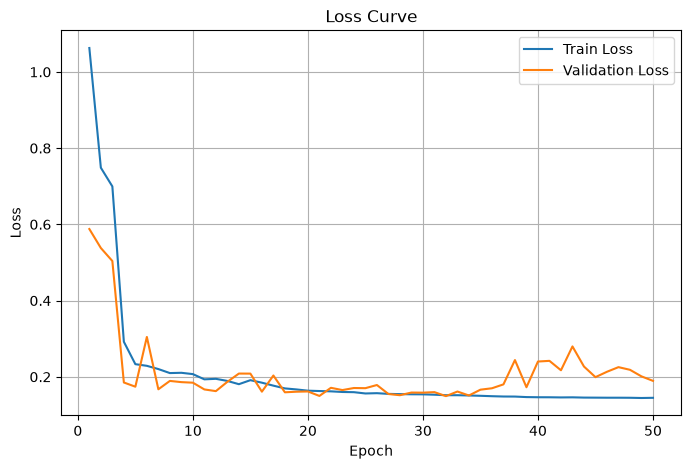

In [32]:
# ============================================================
# Training Curves — Loss
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["train_loss"], label="Train Loss")
plt.plot(history["epoch"], history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.grid(True)
plt.legend()
plt.show()

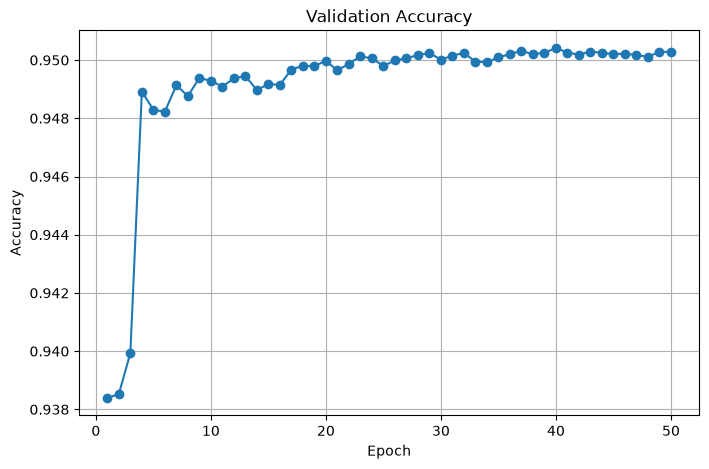

In [33]:
# ============================================================
# Training Curves — Accuracy
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["accuracy"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.grid(True)
plt.show()

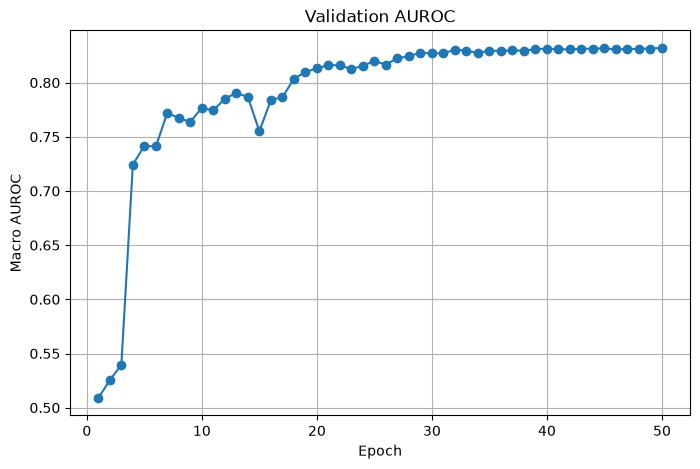

In [34]:
# ============================================================
# Training Curves — AUROC
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["auroc"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Macro AUROC")
plt.title("Validation AUROC")
plt.grid(True)
plt.show()

In [35]:
# ============================================================
# Load Best Model for Final Testing
# ============================================================
# Re-creates a fresh model instance (pretrained=False, since we are
# about to overwrite every weight from the checkpoint anyway) and
# loads the best checkpoint saved during training.

model = DenseNet121Model(num_classes=NUM_CLASSES, pretrained=False).to(DEVICE)

checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("=" * 60)
print("Best Model Loaded Successfully")
print("=" * 60)
print("Best Epoch :", checkpoint["epoch"])
print("Best AUROC :", checkpoint["best_auc"])

Best Model Loaded Successfully
Best Epoch : 50
Best AUROC : 0.8319655395329332


In [36]:
# ============================================================
# Final Evaluation on Held-Out Test Set
# ============================================================
# This is the ONLY time the test set is used — it was never seen
# during training or for checkpoint selection.

test_loss, test_accuracy, test_precision, test_recall, test_f1, test_auroc = validate(
    test_loader, desc="Final Test"
)

print("=" * 70)
print("Final Test Results (Best Model)")
print("=" * 70)
print(f"Test Loss  : {test_loss:.4f}")
print(f"Accuracy   : {test_accuracy:.4f}")
print(f"Precision  : {test_precision:.4f}")
print(f"Recall     : {test_recall:.4f}")
print(f"F1 Score   : {test_f1:.4f}")
print(f"AUROC      : {test_auroc:.4f}")
print("=" * 70)

Final Test Results (Best Model)
Test Loss  : 0.1667
Accuracy   : 0.9506
Precision  : 0.5512
Recall     : 0.1542
F1 Score   : 0.2409
AUROC      : 0.8357
